# Handwritten Character Recognition using CNN

**Task 3 — Beginner-friendly project**

This notebook trains a Convolutional Neural Network (CNN) on the **MNIST handwritten digit dataset** (digits 0–9). TensorFlow downloads the dataset automatically the first time you run the notebook, so you do not need to manually place a CSV file in the project folder.

> Note: MNIST recognizes digits, not A–Z alphabets. For alphabet/character recognition, use the EMNIST dataset as a separate extension.


## 1. Install dependencies

If any package is missing, run this cell.

In [2]:
%pip install -q tensorflow matplotlib numpy scikit-learn

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow version: 2.21.0
GPU available: False


## 3. Load dataset

MNIST has 60,000 training images and 10,000 test images, each 28×28 pixels.

In [4]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)
print("Classes:", np.unique(y_train))

Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)
Classes: [0 1 2 3 4 5 6 7 8 9]


## 4. Display sample images

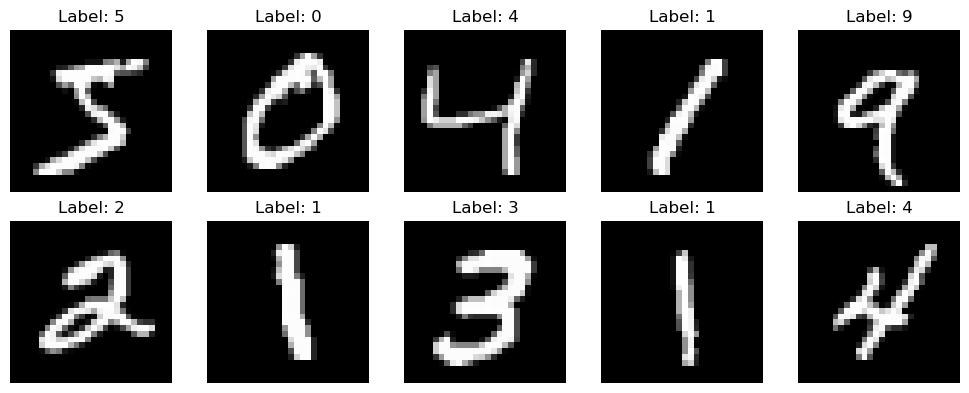

In [5]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## 5. Preprocess images

Pixel values are scaled from 0–255 to 0–1. CNN input needs a channel dimension, so images become 28×28×1.

In [6]:
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Processed training shape:", X_train.shape)
print("Processed test shape:", X_test.shape)

Processed training shape: (60000, 28, 28, 1)
Processed test shape: (10000, 28, 28, 1)


## 6. Build the CNN model

In [7]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Train the model

Early stopping helps reduce overfitting by stopping when validation loss no longer improves.

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=12,
    batch_size=10000,
    validation_split=0.236,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/12
5/5 ━━━━━━━━━━━━━━━━━━━━ 56s 9s/step - accuracy: 0.3021 - loss: 2.1964 - val_accuracy: 0.6373 - val_loss: 1.9368
Epoch 2/12
5/5 ━━━━━━━━━━━━━━━━━━━━ 41s 8s/step - accuracy: 0.6093 - loss: 1.7563 - val_accuracy: 0.7523 - val_loss: 1.3060
Epoch 3/12
5/5 ━━━━━━━━━━━━━━━━━━━━ 43s 9s/step - accuracy: 0.6914 - loss: 1.1756 - val_accuracy: 0.8242 - val_loss: 0.7420
Epoch 4/12
5/5 ━━━━━━━━━━━━━━━━━━━━ 41s 8s/step - accuracy: 0.7623 - loss: 0.7746 - val_accuracy: 0.8648 - val_loss: 0.4832
Epoch 5/12
5/5 ━━━━━━━━━━━━━━━━━━━━ 41s 8s/step - accuracy: 0.8279 - loss: 0.5539 - val_accuracy: 0.8960 - val_loss: 0.3641
Epoch 6/12
5/5 ━━━━━━━━━━━━━━━━━━━━ 42s 8s/step - accuracy: 0.8668 - loss: 0.4387 - val_accuracy: 0.9134 - val_loss: 0.2981
Epoch 7/12
5/5 ━━━━━━━━━━━━━━━━━━━━ 42s 8s/step - accuracy: 0.8919 - loss: 0.3585 - val_accuracy: 0.9257 - val_loss: 0.2508
Epoch 8/12
5/5 ━━━━━━━━━━━━━━━━━━━━ 47s 10s/step - accuracy: 0.9063 - loss: 0.3081 - val_accuracy: 0.9369 - val_loss: 0.2137
Epoch 9

## 8. Plot accuracy and loss

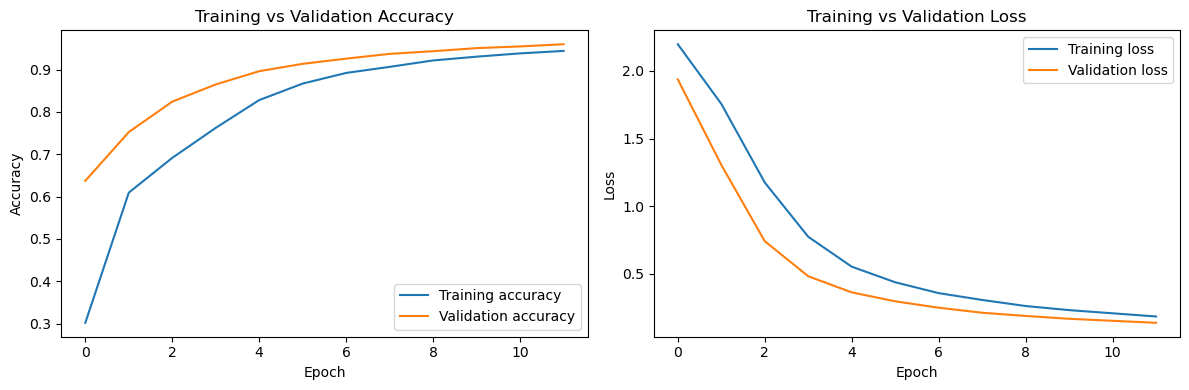

In [9]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()

plt.tight_layout()
plt.show()

## 9. Evaluate on test data

In [10]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4%}")

Test loss: 0.1293
Test accuracy: 96.1500%


## 10. Classification report and confusion matrix

              precision    recall  f1-score   support

           0     0.9709    0.9878    0.9793       980
           1     0.9850    0.9859    0.9855      1135
           2     0.9525    0.9525    0.9525      1032
           3     0.9511    0.9624    0.9567      1010
           4     0.9772    0.9623    0.9697       982
           5     0.9606    0.9563    0.9584       892
           6     0.9790    0.9718    0.9754       958
           7     0.9609    0.9329    0.9467      1028
           8     0.9399    0.9466    0.9432       974
           9     0.9368    0.9544    0.9455      1009

    accuracy                         0.9615     10000
   macro avg     0.9614    0.9613    0.9613     10000
weighted avg     0.9616    0.9615    0.9615     10000



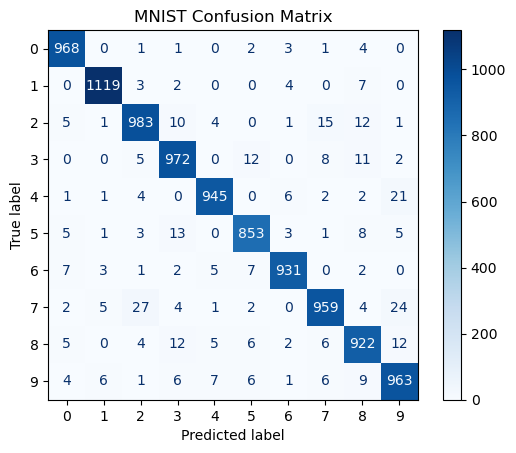

In [11]:
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(y_test, y_pred, digits=4))

cm = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
display.plot(cmap="Blues", values_format="d")
plt.title("MNIST Confusion Matrix")
plt.show()

## 11. Predict a sample image

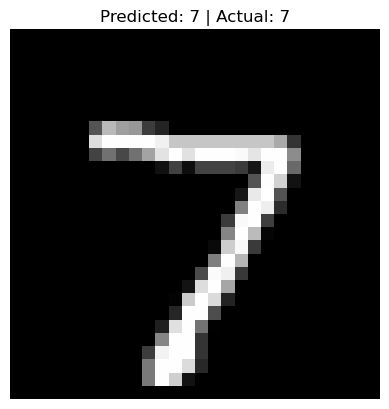

Probabilities for digits 0–9:
[0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]


In [12]:
sample_index = 0
image = X_test[sample_index]
prediction = model.predict(image[np.newaxis, ...], verbose=0)
predicted_digit = int(np.argmax(prediction))

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Predicted: {predicted_digit} | Actual: {y_test[sample_index]}")
plt.axis("off")
plt.show()

print("Probabilities for digits 0–9:")
print(np.round(prediction[0], 3))

## 12. Save the trained model

In [13]:
model.save("handwritten_digit_cnn.keras")
print("Model saved as handwritten_digit_cnn.keras")

Model saved as handwritten_digit_cnn.keras


## 13. Predict your own image (optional)

Put a **28×28 grayscale image** of one handwritten digit in the project folder, named `my_digit.png`. The digit should be centered and have a dark background with a light digit, similar to MNIST. If your image is white background with black ink, the code attempts to invert it.

Run this cell only after adding `my_digit.png`.


In [14]:
from pathlib import Path
from PIL import Image

image_path = Path("my_digit.png")
if image_path.exists():
    img = Image.open(image_path).convert("L").resize((28, 28))
    arr = np.array(img).astype("float32")

    # MNIST convention: dark background, bright digit.
    if arr.mean() > 127:
        arr = 255 - arr

    arr = arr / 255.0
    arr = arr[np.newaxis, ..., np.newaxis]

    probs = model.predict(arr, verbose=0)[0]
    print("Predicted digit:", int(np.argmax(probs)))
    print("Confidence:", f"{float(np.max(probs)):.2%}")

    plt.imshow(arr[0, ..., 0], cmap="gray")
    plt.axis("off")
    plt.show()
else:
    print("Optional image not found. Add my_digit.png to the current working folder to use this cell.")

Optional image not found. Add my_digit.png to the current working folder to use this cell.
